In [1]:
from pathlib import Path
import pandas as pd

data_path = Path("data/processed/tuen_mun_aqhi.csv")
if not data_path.exists():
    data_path = Path("tuen_mun_aqhi.csv")
if not data_path.exists():
    raise FileNotFoundError(
        "Upload tuen_mun_aqhi.csv in Colab, or run from the repository root."
    )

data = pd.read_csv(
    data_path,
    dtype={"aqhi": "float64", "is_substituted": "bool"},
)
data["timestamp"] = pd.to_datetime(
    data["timestamp"], utc=True, errors="raise"
).dt.tz_convert("Asia/Hong_Kong")
data = data.sort_values("timestamp").reset_index(drop=True)

print("First five observations:")
print(data.head().to_string(index=False))


First five observations:
                timestamp  aqhi  is_substituted
2025-04-01 01:00:00+08:00   2.0           False
2025-04-01 02:00:00+08:00   2.0           False
2025-04-01 03:00:00+08:00   2.0           False
2025-04-01 04:00:00+08:00   2.0           False
2025-04-01 05:00:00+08:00   2.0           False


In [2]:
assert list(data.columns) == ["timestamp", "aqhi", "is_substituted"]
assert not data.empty
assert data["timestamp"].notna().all()
assert data["timestamp"].is_unique, "Review duplicate timestamps."

expected_hours = pd.date_range(
    start=data["timestamp"].min(),
    end=data["timestamp"].max(),
    freq="h",
)
missing_hours = expected_hours.difference(pd.DatetimeIndex(data["timestamp"]))
assert len(missing_hours) == 0, "Review missing hours before building targets."

available_aqhi = data["aqhi"].dropna()
assert available_aqhi.isin(range(1, 12)).all(), "Review AQHI codes."

quality_summary = pd.Series({
    "Hourly rows": len(data),
    "Available AQHI readings": int(data["aqhi"].notna().sum()),
    "Missing AQHI readings": int(data["aqhi"].isna().sum()),
    "Duplicate timestamps": int(data["timestamp"].duplicated().sum()),
    "Missing hours": len(missing_hours),
    "Substituted readings": int(data["is_substituted"].sum()),
    "10+ category encoded as 11": int(data["aqhi"].eq(11).sum()),
})
print(quality_summary.to_string())
print("First timestamp:", data["timestamp"].min())
print("Last timestamp:", data["timestamp"].max())


Hourly rows                   10944
Available AQHI readings       10926
Missing AQHI readings            18
Duplicate timestamps              0
Missing hours                     0
Substituted readings           1083
10+ category encoded as 11       15
First timestamp: 2025-04-01 01:00:00+08:00
Last timestamp: 2026-07-01 00:00:00+08:00


In [3]:
high_count = int(available_aqhi.ge(7).sum())
other_count = int(available_aqhi.lt(7).sum())
class_counts = pd.Series({
    "AQHI below 7": other_count,
    "AQHI at least 7": high_count,
})
print(class_counts.to_string())
print(f"High-AQHI share among available readings: {high_count / len(available_aqhi):.2%}")
print(f"Available readings below 7: {other_count / len(available_aqhi):.2%}")
print("Missing measurements remain missing:", int(data["aqhi"].isna().sum()))


AQHI below 7       10621
AQHI at least 7      305
High-AQHI share among available readings: 2.79%
Available readings below 7: 97.21%
Missing measurements remain missing: 18


In [4]:
import hashlib
import json
import platform
import warnings
import numpy as np
import matplotlib.pyplot as plt
import sklearn
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import ParameterGrid, TimeSeriesSplit
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    confusion_matrix, precision_score, recall_score, f1_score,
    accuracy_score, average_precision_score, precision_recall_curve,
    ConfusionMatrixDisplay,
)

warnings.filterwarnings('error', category=ConvergenceWarning)
warnings.filterwarnings('error', category=RuntimeWarning)
SEED = 3004
HORIZON = pd.Timedelta(hours=6)
TEST_START = pd.Timestamp('2026-04-01 00:00', tz='Asia/Hong_Kong')
TEST_END = pd.Timestamp('2026-07-01 00:00', tz='Asia/Hong_Kong')
output_dir = Path('outputs/model-evaluation')
figure_dir = output_dir / 'figures'
figure_dir.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'font.size': 10, 'figure.dpi': 120})

In [5]:
observations = data.set_index('timestamp')
features = pd.DataFrame(index=observations.index)
features['aqhi_now'] = observations['aqhi']
for lag in (1, 2, 3):
    features[f'aqhi_lag_{lag}h'] = observations['aqhi'].reindex(
        features.index - pd.Timedelta(hours=lag)
    ).to_numpy()
features['aqhi_change_3h'] = features['aqhi_now'] - features['aqhi_lag_3h']
features['hour_sin'] = np.sin(2 * np.pi * features.index.hour / 24)
features['hour_cos'] = np.cos(2 * np.pi * features.index.hour / 24)
feature_columns = list(features.columns)

samples = features.copy()
samples['target_time'] = samples.index + HORIZON
samples['actual_aqhi'] = observations['aqhi'].reindex(samples.target_time).to_numpy()
samples['input_substituted'] = observations['is_substituted'].to_numpy()
samples['target_substituted'] = observations['is_substituted'].reindex(
    samples.target_time, fill_value=False
).to_numpy()
samples['any_input_substituted'] = samples['input_substituted']
for lag in (1, 2, 3):
    lag_flag = observations['is_substituted'].reindex(
        samples.index - pd.Timedelta(hours=lag), fill_value=False
    ).to_numpy()
    samples['any_input_substituted'] |= lag_flag

missing_features = samples[feature_columns].isna().any(axis=1)
missing_targets = samples['actual_aqhi'].isna()
complete = samples.loc[~missing_features & ~missing_targets].copy()
complete['actual_class'] = complete['actual_aqhi'].ge(7).astype(int)
train = complete.loc[(complete.index < TEST_START) & (complete.target_time < TEST_START)].copy()
test = complete.loc[(complete.index >= TEST_START) & (complete.target_time <= TEST_END)].copy()
assert len(train) and len(test)
assert train.target_time.max() < test.index.min()
assert train.index.intersection(test.index).empty
assert train.actual_class.nunique() == 2
assert test.actual_class.nunique() == 2

split_summary = pd.DataFrame([
    {'split': name, 'samples': len(frame), 'positive_samples': int(frame.actual_class.sum()),
     'negative_samples': int(frame.actual_class.eq(0).sum()),
     'first_input_time': frame.index.min(), 'last_input_time': frame.index.max(),
     'last_target_time': frame.target_time.max(),
     'substituted_targets': int(frame.target_substituted.sum())}
    for name, frame in [('train', train), ('test', test)]
])
split_summary.to_csv(output_dir / 'split_summary.csv', index=False)
exclusions = pd.Series({
    'input_rows': len(samples), 'rows_with_missing_features': int(missing_features.sum()),
    'rows_with_missing_or_unavailable_targets': int(missing_targets.sum()),
    'rows_with_both': int((missing_features & missing_targets).sum()),
    'complete_rows': len(complete),
    'excluded_complete_rows_across_split_boundary': len(complete) - len(train) - len(test),
})
exclusions.to_csv(output_dir / 'sample_accounting.csv', header=['count'])
print(split_summary.to_string(index=False))
print(exclusions.to_string())
print(train[feature_columns + ['target_time', 'actual_class']].head().to_string())

split  samples  positive_samples  negative_samples          first_input_time           last_input_time          last_target_time  substituted_targets
train     8732               271              8461 2025-04-01 04:00:00+08:00 2026-03-31 17:00:00+08:00 2026-03-31 23:00:00+08:00                  411
 test     2153                34              2119 2026-04-01 00:00:00+08:00 2026-06-30 18:00:00+08:00 2026-07-01 00:00:00+08:00                  655
input_rows                                      10944
rows_with_missing_features                         33
rows_with_missing_or_unavailable_targets           24
rows_with_both                                      4
complete_rows                                   10891
excluded_complete_rows_across_split_boundary        6
                           aqhi_now  aqhi_lag_1h  aqhi_lag_2h  aqhi_lag_3h  aqhi_change_3h  hour_sin      hour_cos               target_time  actual_class
timestamp                                                              

In [6]:
X_train, y_train = train[feature_columns], train.actual_class
X_test, y_test = test[feature_columns], test.actual_class
splitter = TimeSeriesSplit(n_splits=3, gap=6)
folds = list(splitter.split(X_train))
fold_records = []
for number, (fit_rows, validation_rows) in enumerate(folds, start=1):
    assert train.iloc[fit_rows].target_time.max() < train.index[validation_rows].min()
    assert y_train.iloc[fit_rows].nunique() == 2
    assert y_train.iloc[validation_rows].sum() > 0
    fold_records.append({
        'fold': number, 'fit_samples': len(fit_rows), 'validation_samples': len(validation_rows),
        'fit_last_target': train.iloc[fit_rows].target_time.max(),
        'validation_start': train.index[validation_rows].min(),
        'validation_end': train.index[validation_rows].max(),
        'validation_positives': int(y_train.iloc[validation_rows].sum()),
    })
pd.DataFrame(fold_records).to_csv(output_dir / 'validation_folds.csv', index=False)

model_specs = {
    'Decision Tree': (DecisionTreeClassifier(random_state=SEED), {
        'max_depth': [3, 5], 'min_samples_leaf': [10, 30], 'class_weight': [None, 'balanced']}),
    'Random Forest': (RandomForestClassifier(n_estimators=150, n_jobs=-1, random_state=SEED), {
        'max_depth': [5, None], 'min_samples_leaf': [5, 20], 'class_weight': [None, 'balanced']}),
    'Logistic Regression': (make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, random_state=SEED)), {
        'logisticregression__C': [0.1, 1.0, 10.0], 'logisticregression__class_weight': [None, 'balanced']}),
    'KNN': (make_pipeline(StandardScaler(), KNeighborsClassifier()), {
        'kneighborsclassifier__n_neighbors': [5, 15, 31], 'kneighborsclassifier__weights': ['uniform', 'distance']}),
    'SVM': (make_pipeline(StandardScaler(), SVC(kernel='rbf', gamma='scale', cache_size=512, random_state=SEED)), {
        'svc__C': [0.1, 1.0, 10.0], 'svc__class_weight': [None, 'balanced']}),
}

def scores_for(estimator, X):
    if hasattr(estimator, 'predict_proba'):
        scores = estimator.predict_proba(X)[:, 1]
    else:
        scores = estimator.decision_function(X)
    assert np.isfinite(scores).all()
    return scores

def select_threshold(truth, scores):
    precision, recall, thresholds = precision_recall_curve(truth, scores)
    f1_values = np.divide(2 * precision[:-1] * recall[:-1], precision[:-1] + recall[:-1],
                          out=np.zeros(len(thresholds)), where=(precision[:-1] + recall[:-1]) > 0)
    best = max(range(len(thresholds)), key=lambda i: (f1_values[i], precision[i], thresholds[i]))
    return float(thresholds[best]), float(f1_values[best])

selected = {}
search_records = []
for name, (base_estimator, grid) in model_specs.items():
    candidates = []
    for parameters in ParameterGrid(grid):
        validation_scores, validation_truth, validation_times = [], [], []
        for fit_rows, validation_rows in folds:
            estimator = clone(base_estimator).set_params(**parameters)
            estimator.fit(X_train.iloc[fit_rows], y_train.iloc[fit_rows])
            validation_scores.extend(scores_for(estimator, X_train.iloc[validation_rows]))
            validation_truth.extend(y_train.iloc[validation_rows])
            validation_times.extend(X_train.index[validation_rows])
        validation_scores = np.asarray(validation_scores)
        validation_truth = np.asarray(validation_truth)
        threshold, validation_f1 = select_threshold(validation_truth, validation_scores)
        result = {'method': name, 'parameters': parameters, 'threshold': threshold,
                  'validation_f1': validation_f1,
                  'validation_precision': precision_score(validation_truth, validation_scores >= threshold, zero_division=0),
                  'validation_recall': recall_score(validation_truth, validation_scores >= threshold, zero_division=0)}
        search_records.append({**result, 'parameters': json.dumps(parameters, sort_keys=True)})
        candidates.append((result, validation_scores, validation_truth, validation_times))
    result, scores, truth, times = max(candidates, key=lambda row: (
        row[0]['validation_f1'], row[0]['validation_precision']))
    selected[name] = result
    print(name, json.dumps(result), flush=True)

pd.DataFrame(search_records).to_csv(output_dir / 'validation_search.csv', index=False)
validation_winner = max(selected, key=lambda name: (selected[name]['validation_f1'], selected[name]['validation_precision']))
print('Validation-selected model:', validation_winner)

Decision Tree {"method": "Decision Tree", "parameters": {"class_weight": null, "max_depth": 5, "min_samples_leaf": 10}, "threshold": 0.2727272727272727, "validation_f1": 0.25161290322580643, "validation_precision": 0.3023255813953488, "validation_recall": 0.2154696132596685}


Random Forest {"method": "Random Forest", "parameters": {"class_weight": "balanced", "max_depth": 5, "min_samples_leaf": 5}, "threshold": 0.6614631061223304, "validation_f1": 0.25576519916142565, "validation_precision": 0.20608108108108109, "validation_recall": 0.3370165745856354}


Logistic Regression {"method": "Logistic Regression", "parameters": {"logisticregression__C": 10.0, "logisticregression__class_weight": "balanced"}, "threshold": 0.8879231134881003, "validation_f1": 0.3438395415472779, "validation_precision": 0.35714285714285715, "validation_recall": 0.3314917127071823}


KNN {"method": "KNN", "parameters": {"kneighborsclassifier__n_neighbors": 31, "kneighborsclassifier__weights": "uniform"}, "threshold": 0.12903225806451613, "validation_f1": 0.20987654320987656, "validation_precision": 0.16721311475409836, "validation_recall": 0.281767955801105}


SVM {"method": "SVM", "parameters": {"svc__C": 0.1, "svc__class_weight": "balanced"}, "threshold": 0.6790136904498294, "validation_f1": 0.21811460258780035, "validation_precision": 0.1638888888888889, "validation_recall": 0.3259668508287293}


Validation-selected model: Logistic Regression


In [7]:
def evaluate_predictions(name, truth, predicted):
    tn, fp, fn, tp = confusion_matrix(truth, predicted, labels=[0, 1]).ravel()
    return {'method': name, 'samples': len(truth), 'positive_samples': int(np.sum(truth)),
            'true_positive': int(tp), 'false_negative': int(fn), 'false_positive': int(fp),
            'true_negative': int(tn), 'precision': precision_score(truth, predicted, zero_division=0),
            'recall': recall_score(truth, predicted, zero_division=0),
            'f1': f1_score(truth, predicted, zero_division=0), 'accuracy': accuracy_score(truth, predicted)}

fitted_models, predictions = {}, {}
metric_records, prediction_frames = [], []
for name, result in selected.items():
    estimator = clone(model_specs[name][0]).set_params(**result['parameters'])
    estimator.fit(X_train, y_train)
    scores = scores_for(estimator, X_test)
    predicted = (scores >= result['threshold']).astype(int)
    fitted_models[name] = estimator
    predictions[name] = (scores, predicted)
predictions['Persistence baseline'] = (test.aqhi_now.ge(7).astype(float).to_numpy(), test.aqhi_now.ge(7).astype(int).to_numpy())

for name, (scores, predicted) in predictions.items():
    metrics = evaluate_predictions(name, y_test, predicted)
    metrics['average_precision'] = average_precision_score(y_test, scores)
    metric_records.append(metrics)
    frame = test[['target_time', 'actual_aqhi', 'actual_class', 'input_substituted',
                  'any_input_substituted', 'target_substituted']].copy().reset_index()
    frame['method'], frame['score'], frame['predicted_class'] = name, scores, predicted
    frame['decision_threshold'] = selected[name]['threshold'] if name in selected else 0.5
    frame['score_type'] = 'decision_function' if name == 'SVM' else ('binary_baseline' if name == 'Persistence baseline' else 'predict_proba')
    prediction_frames.append(frame)

metrics = pd.DataFrame(metric_records)
prediction_table = pd.concat(prediction_frames, ignore_index=True)
metrics.to_csv(output_dir / 'test_metrics.csv', index=False)
prediction_table.to_csv(output_dir / 'test_predictions.csv', index=False)

subgroup_records = []
for group, mask in [('target_from_tuen_mun', ~test.target_substituted),
                    ('target_substituted', test.target_substituted),
                    ('all_inputs_and_target_from_tuen_mun', ~test.any_input_substituted & ~test.target_substituted)]:
    if mask.any():
        for name, (_, predicted) in predictions.items():
            subgroup_records.append({'group': group, **evaluate_predictions(name, y_test.loc[mask], predicted[mask.to_numpy()])})
pd.DataFrame(subgroup_records).to_csv(output_dir / 'test_subgroup_metrics.csv', index=False)
assert prediction_table.groupby('method').size().eq(len(test)).all()
assert metrics[['true_positive','false_negative','false_positive','true_negative']].sum(axis=1).eq(len(test)).all()
assert metrics.positive_samples.eq(int(y_test.sum())).all()
print(metrics.sort_values('f1', ascending=False).to_string(index=False))

              method  samples  positive_samples  true_positive  false_negative  false_positive  true_negative  precision   recall       f1  accuracy  average_precision
       Decision Tree     2153                34              7              27               9           2110   0.437500 0.205882 0.280000  0.983279           0.195821
 Logistic Regression     2153                34             10              24              33           2086   0.232558 0.294118 0.259740  0.973525           0.234078
       Random Forest     2153                34             17              17              84           2035   0.168317 0.500000 0.251852  0.953089           0.160466
                 SVM     2153                34             16              18              97           2022   0.141593 0.470588 0.217687  0.946586           0.150868
                 KNN     2153                34             11              23              59           2060   0.157143 0.323529 0.211538  0.961914           0

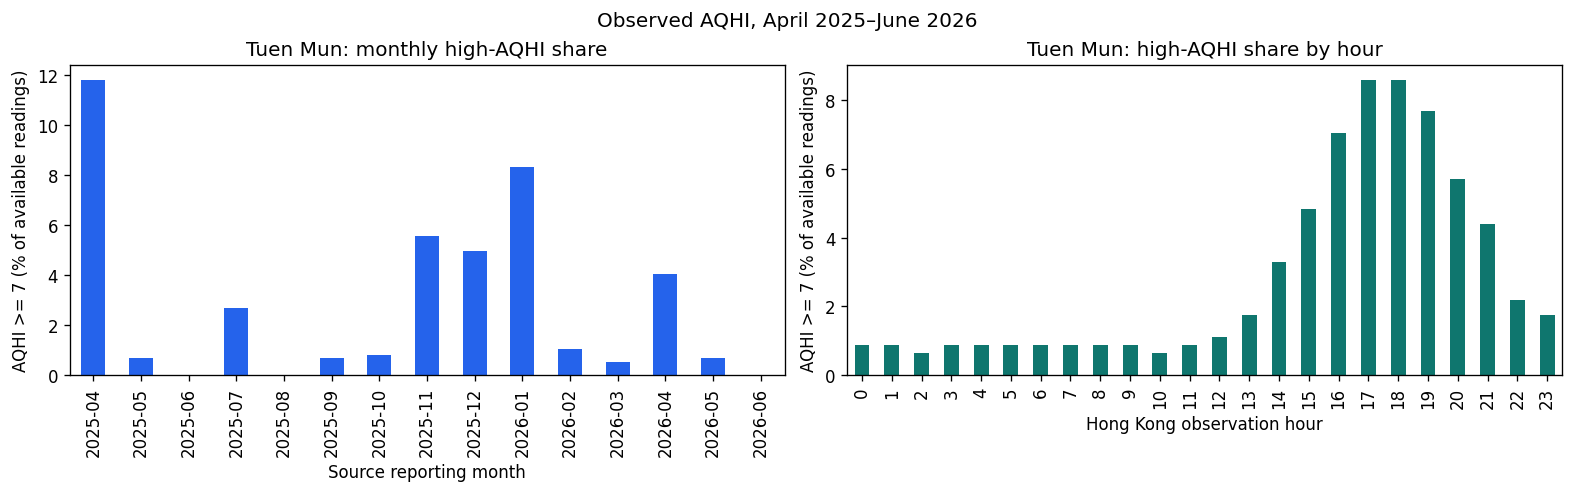

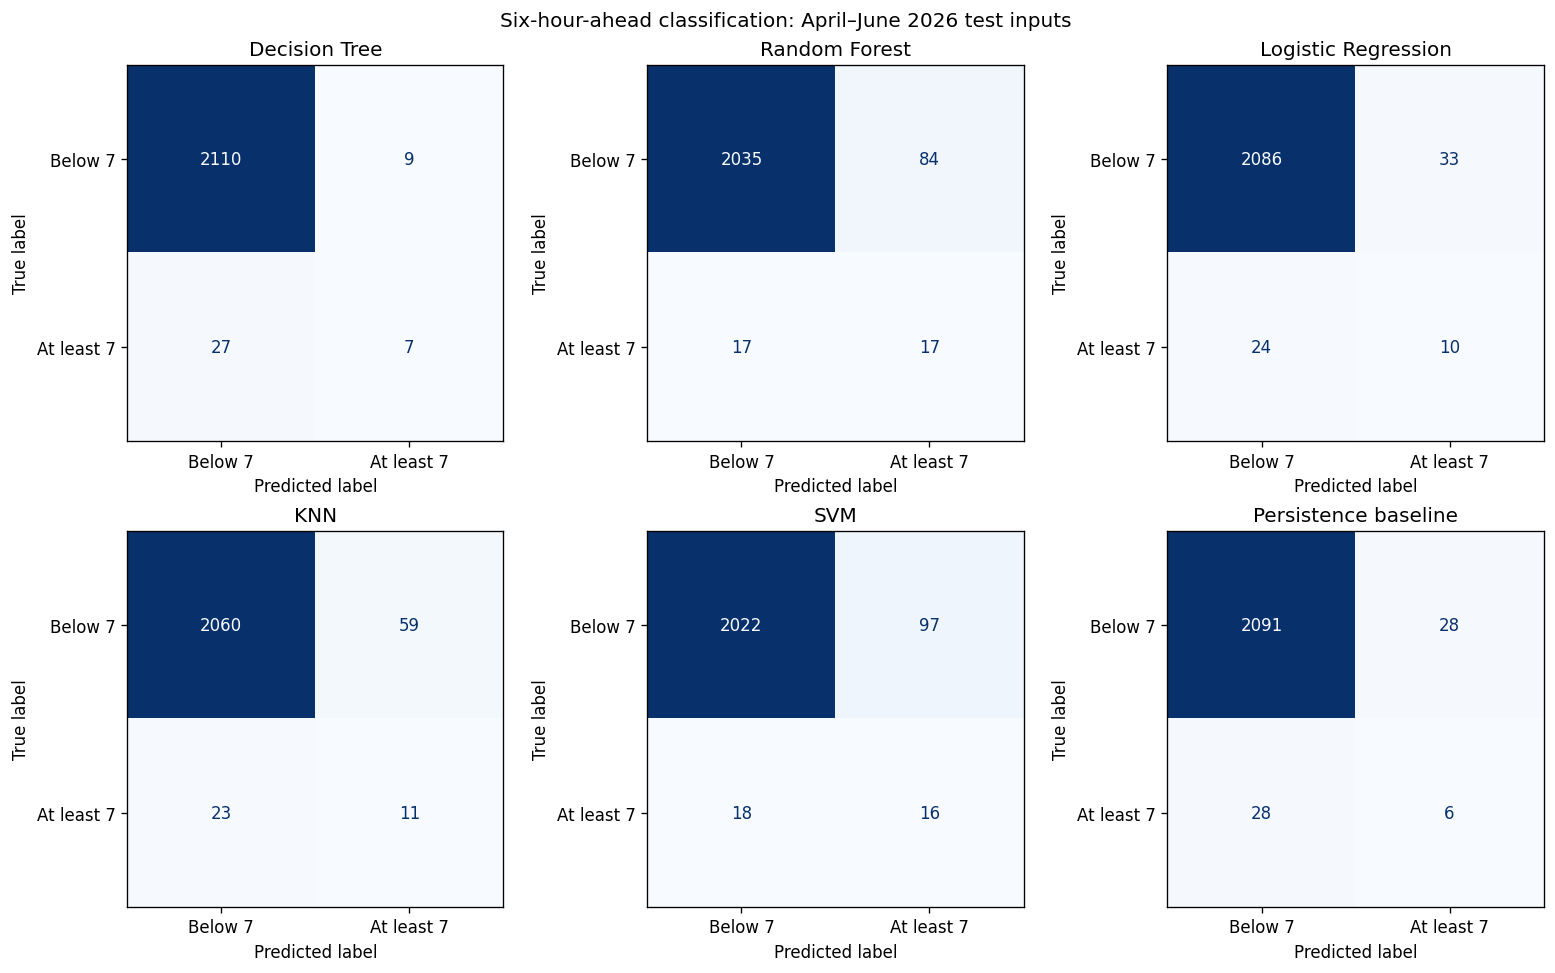

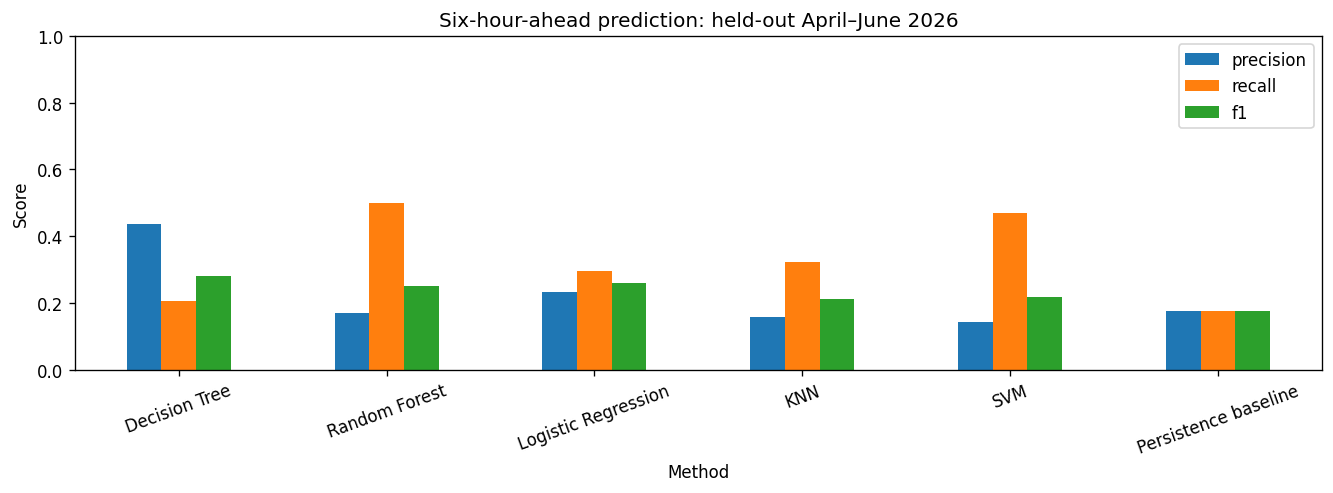

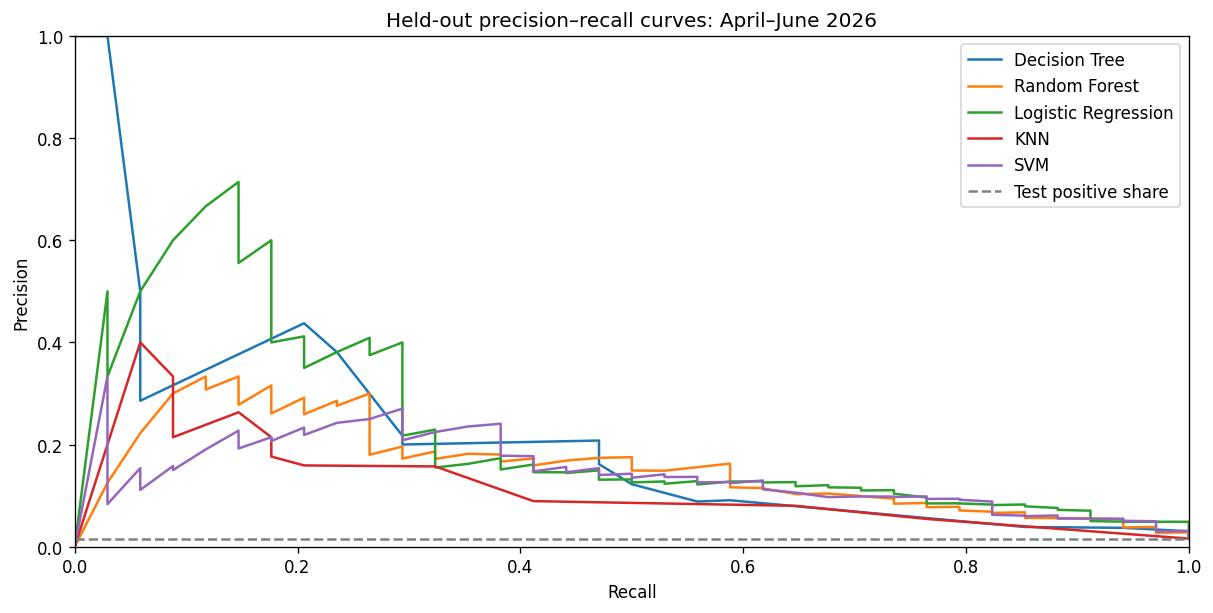

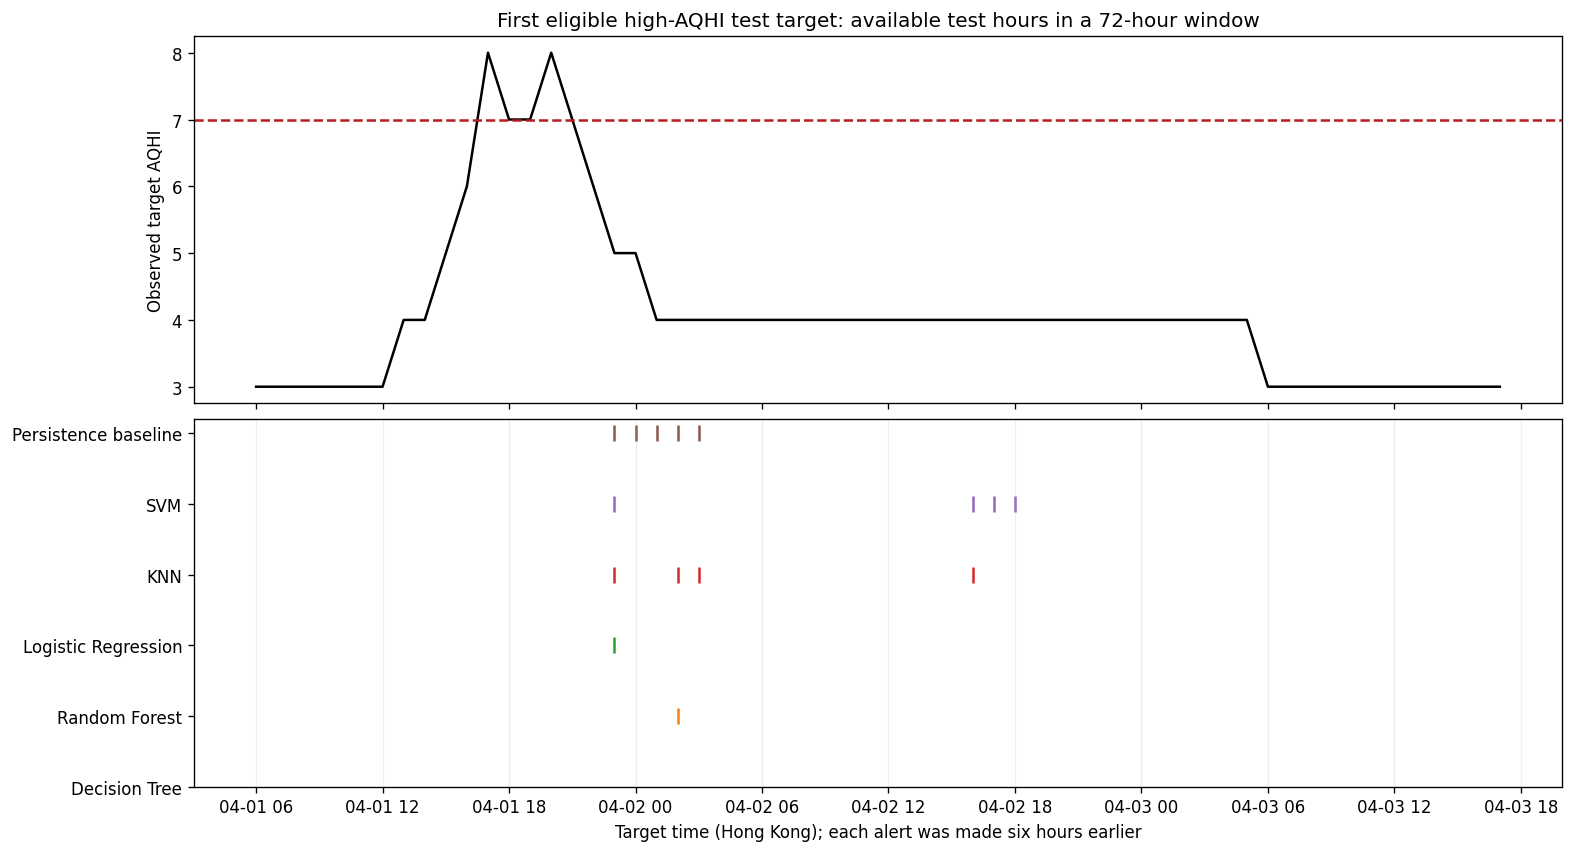

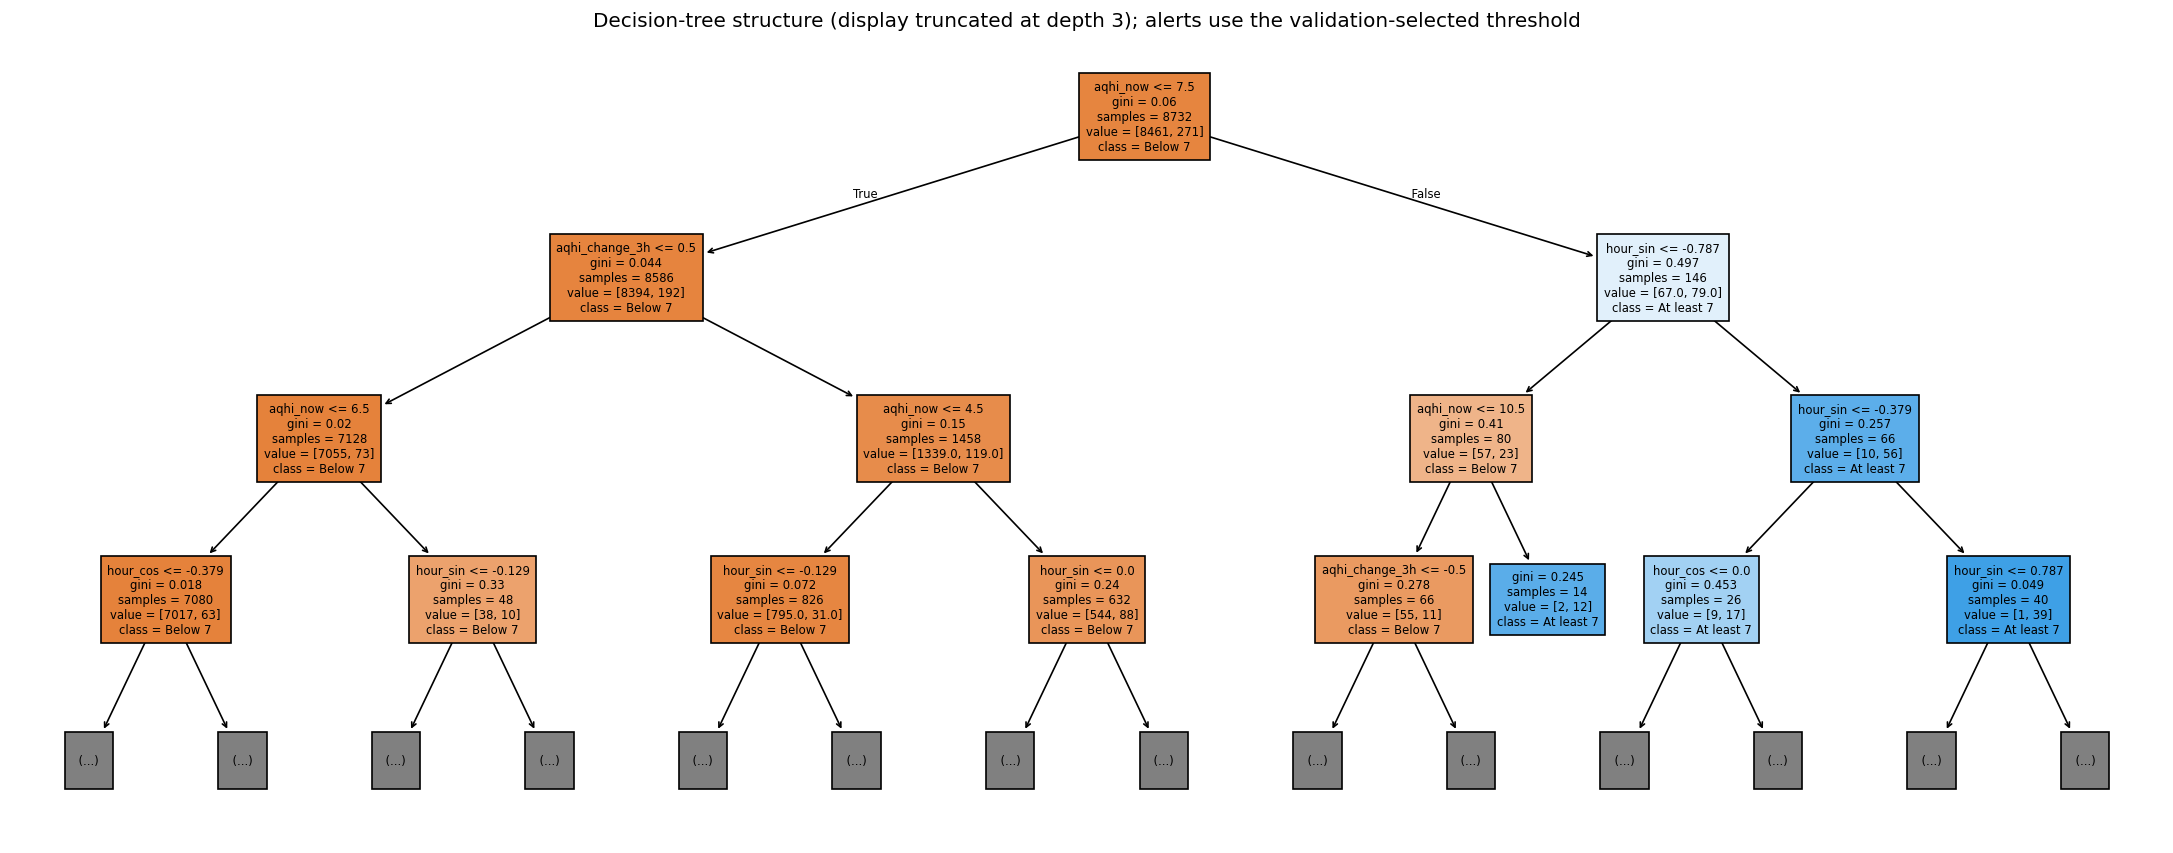

Outputs: /Users/damon/school/26-27/term1/CDS3004/tmp/guided-model/outputs/model-evaluation
Validation-selected method: Logistic Regression


In [8]:
monthly = data.assign(month=(data.timestamp - pd.Timedelta(hours=1)).dt.strftime('%Y-%m')).groupby('month').aqhi.agg(
    valid='count', high=lambda s: s.ge(7).sum())
hourly = data.assign(hour=data.timestamp.dt.hour).groupby('hour').aqhi.agg(
    valid='count', high=lambda s: s.ge(7).sum())
fig, axes = plt.subplots(1, 2, figsize=(13, 4), layout='constrained')
(100 * monthly.high / monthly.valid).plot.bar(ax=axes[0], color='#2563eb')
axes[0].set(title='Tuen Mun: monthly high-AQHI share', xlabel='Source reporting month', ylabel='AQHI >= 7 (% of available readings)')
(100 * hourly.high / hourly.valid).plot.bar(ax=axes[1], color='#0f766e')
axes[1].set(title='Tuen Mun: high-AQHI share by hour', xlabel='Hong Kong observation hour', ylabel='AQHI >= 7 (% of available readings)')
fig.suptitle('Observed AQHI, April 2025–June 2026')
fig.savefig(figure_dir / 'aqhi_distribution.png', dpi=160)
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(13, 8), layout='constrained')
for ax, (name, (_, predicted)) in zip(axes.flat, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, predicted, labels=[0,1],
        display_labels=['Below 7', 'At least 7'], ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(name)
fig.suptitle('Six-hour-ahead classification: April–June 2026 test inputs')
fig.savefig(figure_dir / 'confusion_matrices.png', dpi=160)
plt.show()

fig, ax = plt.subplots(figsize=(11, 4), layout='constrained')
metrics.set_index('method')[['precision','recall','f1']].plot.bar(ax=ax)
ax.set(title='Six-hour-ahead prediction: held-out April–June 2026', ylabel='Score', xlabel='Method', ylim=(0,1))
ax.tick_params(axis='x', labelrotation=20)
fig.savefig(figure_dir / 'model_comparison.png', dpi=160)
plt.show()

fig, ax = plt.subplots(figsize=(10, 5), layout='constrained')
for name, (scores, _) in predictions.items():
    if name != 'Persistence baseline':
        precision, recall, _ = precision_recall_curve(y_test, scores)
        ax.plot(recall, precision, label=name)
ax.axhline(y_test.mean(), linestyle='--', color='gray', label='Test positive share')
ax.set(title='Held-out precision–recall curves: April–June 2026', xlabel='Recall', ylabel='Precision', xlim=(0,1), ylim=(0,1))
ax.legend()
fig.savefig(figure_dir / 'precision_recall.png', dpi=160)
plt.show()

first_event = test.loc[test.actual_class.eq(1), 'target_time'].iloc[0]
window_start, window_end = first_event - pd.Timedelta(hours=24), first_event + pd.Timedelta(hours=48)
window = test.target_time.between(window_start, window_end)
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True, layout='constrained')
axes[0].plot(test.loc[window, 'target_time'], test.loc[window, 'actual_aqhi'], color='black')
axes[0].axhline(7, linestyle='--', color='#b91c1c')
axes[0].set(ylabel='Observed target AQHI', title='First eligible high-AQHI test target: available test hours in a 72-hour window')
for position, (name, (_, predicted)) in enumerate(predictions.items()):
    alerts = window.to_numpy() & (predicted == 1)
    axes[1].scatter(test.loc[alerts,'target_time'], np.full(alerts.sum(), position), marker='|', s=90)
axes[1].set(yticks=range(len(predictions)), yticklabels=list(predictions), xlabel='Target time (Hong Kong); each alert was made six hours earlier')
axes[1].grid(axis='x', alpha=0.2)
fig.savefig(figure_dir / 'first_event_timeline.png', dpi=160)
plt.show()

fig, ax = plt.subplots(figsize=(18, 7), layout='constrained')
plot_tree(fitted_models['Decision Tree'], feature_names=feature_columns,
          class_names=['Below 7','At least 7'], max_depth=3, filled=True, ax=ax, fontsize=7)
ax.set_title('Decision-tree structure (display truncated at depth 3); alerts use the validation-selected threshold')
fig.savefig(figure_dir / 'decision_tree.png', dpi=160)
plt.show()

run_record = {
    'seed': SEED, 'forecast_hours': 6, 'positive_definition': 'target AQHI >= 7',
    'input_sha256': hashlib.sha256(data_path.read_bytes()).hexdigest(),
    'features': feature_columns, 'test_start_inclusive': TEST_START.isoformat(),
    'test_target_end_inclusive': TEST_END.isoformat(),
    'source_hour24': 'next-day midnight, Hong Kong hour endpoint',
    'aqhi_10plus_encoding': 11, 'missing_data': 'complete cases; no interpolation',
    'substitution_policy': 'retain flagged readings; fixed-model subgroup metrics exported',
    'primary_selection_metric': 'pooled chronological validation F1; ties prefer higher precision',
    'validation': {'folds':3, 'gap_rows':6, 'assertion':'fit target times precede validation input times'},
    'selected_models': selected, 'validation_winner': validation_winner,
    'versions': {'python':platform.python_version(), 'pandas':pd.__version__, 'numpy':np.__version__, 'sklearn':sklearn.__version__},
    'test_sample_count':len(test), 'test_positive_count':int(y_test.sum()),
    'timeline_selection':'first eligible positive target, 24h before to 48h after',
}
(output_dir / 'model_settings.json').write_text(json.dumps(run_record, indent=2), encoding='utf-8')
print('Outputs:', output_dir.resolve())
print('Validation-selected method:', validation_winner)

In [9]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

dbscan_dir = output_dir / 'dbscan'
dbscan_dir.mkdir(exist_ok=True)
dbscan_features = ['aqhi_now', 'aqhi_change_3h', 'hour_sin', 'hour_cos']
dbscan_scaler = StandardScaler()
cluster_train_X = dbscan_scaler.fit_transform(train[dbscan_features])
cluster_test_X = dbscan_scaler.transform(test[dbscan_features])
DBSCAN_EPS = 0.75
DBSCAN_MIN_SAMPLES = 30

density_records = []
for eps in [0.35, 0.5, 0.75, 1.0]:
    for minimum in [15, 30, 60]:
        trial = DBSCAN(eps=eps, min_samples=minimum, n_jobs=-1).fit(cluster_train_X)
        labels = trial.labels_
        density_records.append({
            'eps': eps, 'min_samples': minimum,
            'clusters': len(set(labels) - {-1}),
            'noise_samples': int((labels == -1).sum()),
            'noise_fraction': float((labels == -1).mean()),
            'core_samples': len(trial.core_sample_indices_),
            'reference_setting': eps == DBSCAN_EPS and minimum == DBSCAN_MIN_SAMPLES,
        })
pd.DataFrame(density_records).to_csv(dbscan_dir / 'parameter_sensitivity.csv', index=False)

density_model = DBSCAN(eps=DBSCAN_EPS, min_samples=DBSCAN_MIN_SAMPLES, n_jobs=-1).fit(cluster_train_X)
assert len(density_model.core_sample_indices_) > 0
core_labels = density_model.labels_[density_model.core_sample_indices_]
core_neighbors = NearestNeighbors(n_neighbors=1).fit(density_model.components_)
test_core_distances, test_core_indices = core_neighbors.kneighbors(cluster_test_X)
test_cluster_labels = np.where(
    test_core_distances[:, 0] <= DBSCAN_EPS,
    core_labels[test_core_indices[:, 0]],
    -1,
)
print(pd.DataFrame(density_records).to_string(index=False))
print('Reference clusters:', len(set(density_model.labels_) - {-1}))

 eps  min_samples  clusters  noise_samples  noise_fraction  core_samples  reference_setting
0.35           15       165           1153        0.132043          7579              False
0.35           30       112           2303        0.263743          6429              False
0.35           60        38           5427        0.621507          3305              False
0.50           15        20            516        0.059093          8118              False
0.50           30        13            772        0.088410          7846              False
0.50           60        11           1285        0.147160          7199              False
0.75           15         5            187        0.021415          8457              False
0.75           30         5            356        0.040770          8201               True
0.75           60         3            590        0.067568          7912              False
1.00           15         7            119        0.013628          8534        

In [10]:
cluster_frames = []
for split_name, frame, labels in [
    ('train', train, density_model.labels_),
    ('test', test, test_cluster_labels),
]:
    assignments = frame[dbscan_features + ['target_time', 'actual_aqhi', 'actual_class',
                        'any_input_substituted', 'target_substituted']].copy().reset_index()
    assignments['split'] = split_name
    assignments['cluster'] = labels
    assignments['is_noise_or_outside'] = assignments.cluster.eq(-1)
    if split_name == 'train':
        assignments['is_training_core'] = False
        assignments.loc[density_model.core_sample_indices_, 'is_training_core'] = True
    else:
        assignments['nearest_training_core_distance'] = test_core_distances[:, 0]
    assignments.to_csv(dbscan_dir / f'{split_name}_assignments.csv', index=False)
    cluster_frames.append(assignments)
cluster_assignments = pd.concat(cluster_frames, ignore_index=True)
cluster_summary = cluster_assignments.groupby(['split', 'cluster']).agg(
    samples=('actual_class', 'size'),
    future_high_samples=('actual_class', 'sum'),
    future_high_rate=('actual_class', 'mean'),
    mean_current_aqhi=('aqhi_now', 'mean'),
    mean_change_3h=('aqhi_change_3h', 'mean'),
    substituted_targets=('target_substituted', 'sum'),
).reset_index()
cluster_summary.to_csv(dbscan_dir / 'cluster_summary.csv', index=False)
assert cluster_summary.groupby('split').samples.sum().to_dict() == {'train': len(train), 'test': len(test)}
assert cluster_summary.groupby('split').future_high_samples.sum().to_dict() == {
    'train': int(y_train.sum()), 'test': int(y_test.sum())}

clustering_settings = {
    'analysis_type': 'exploratory density clustering; cluster labels are not high-AQHI predictions',
    'features': dbscan_features,
    'eps': DBSCAN_EPS, 'min_samples': DBSCAN_MIN_SAMPLES,
    'parameter_policy': 'reference setting 0.75/30 with a training-only sensitivity grid; future labels and test results are not used to choose settings',
    'scaling_fit': 'training inputs only',
    'scaler_mean': dbscan_scaler.mean_.tolist(),
    'scaler_scale': dbscan_scaler.scale_.tolist(),
    'train_assignment': 'native DBSCAN labels; -1 denotes training noise',
    'test_assignment': 'custom frozen nearest-training-core rule: assign its label within eps, otherwise -1; no DBSCAN refit on test data',
    'test_minus_one_meaning': 'outside all fitted training core neighborhoods',
    'future_labels': 'used after clustering for descriptive association tables only',
    'test_statistics': 'exploratory summaries on the already inspected holdout',
    'projection_plot': 'current AQHI versus three-hour change; clustering also includes cyclic hour features',
    'input_sha256': hashlib.sha256(data_path.read_bytes()).hexdigest(),
}
(dbscan_dir / 'settings.json').write_text(json.dumps(clustering_settings, indent=2), encoding='utf-8')
print(cluster_summary.to_string(index=False))

split  cluster  samples  future_high_samples  future_high_rate  mean_current_aqhi  mean_change_3h  substituted_targets
 test       -1       56                    3          0.053571           5.535714        0.178571                    2
 test        0     1501                   11          0.007328           2.844770        0.000000                  476
 test        1      254                   14          0.055118           3.811024        1.000000                   81
 test        2       26                    6          0.230769           5.692308        2.000000                    2
 test        3      315                    0          0.000000           2.984127       -1.000000                   94
 test        4        1                    0          0.000000           5.000000       -2.000000                    0
train       -1      356                   92          0.258427           6.103933        0.002809                   14
train        0     5527                   60    

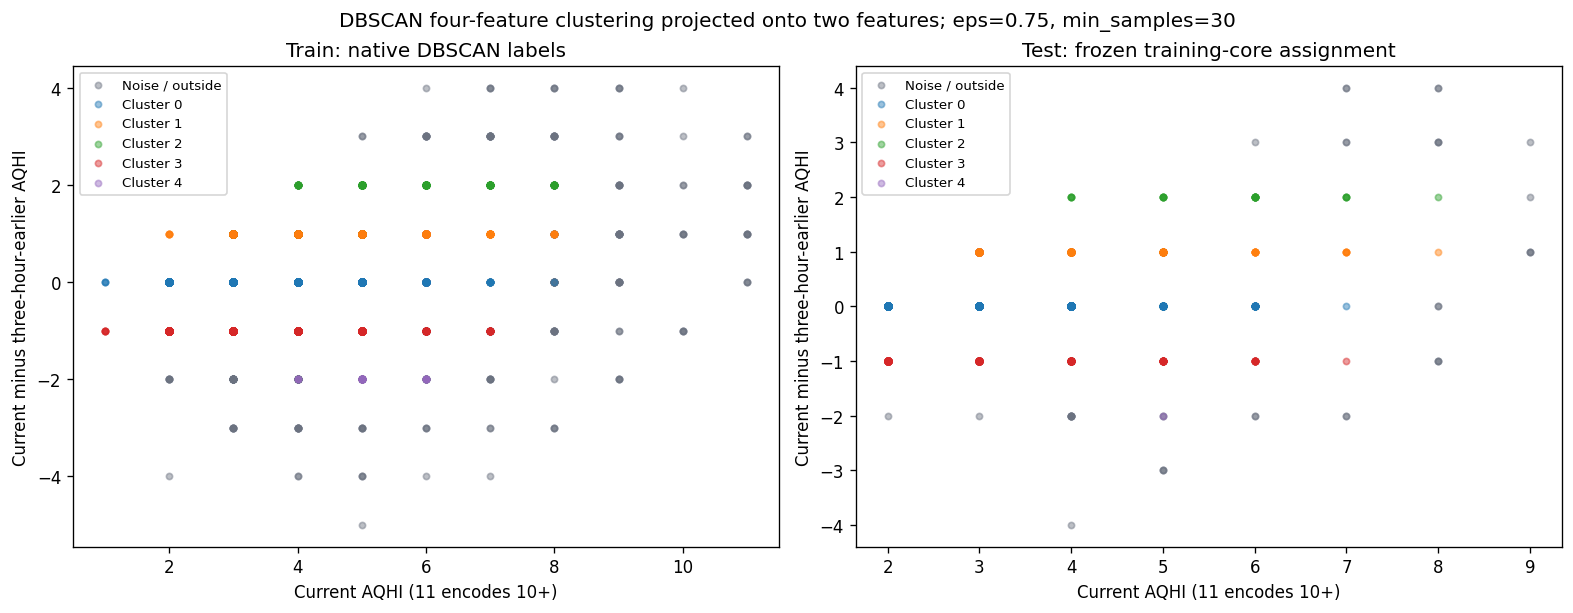

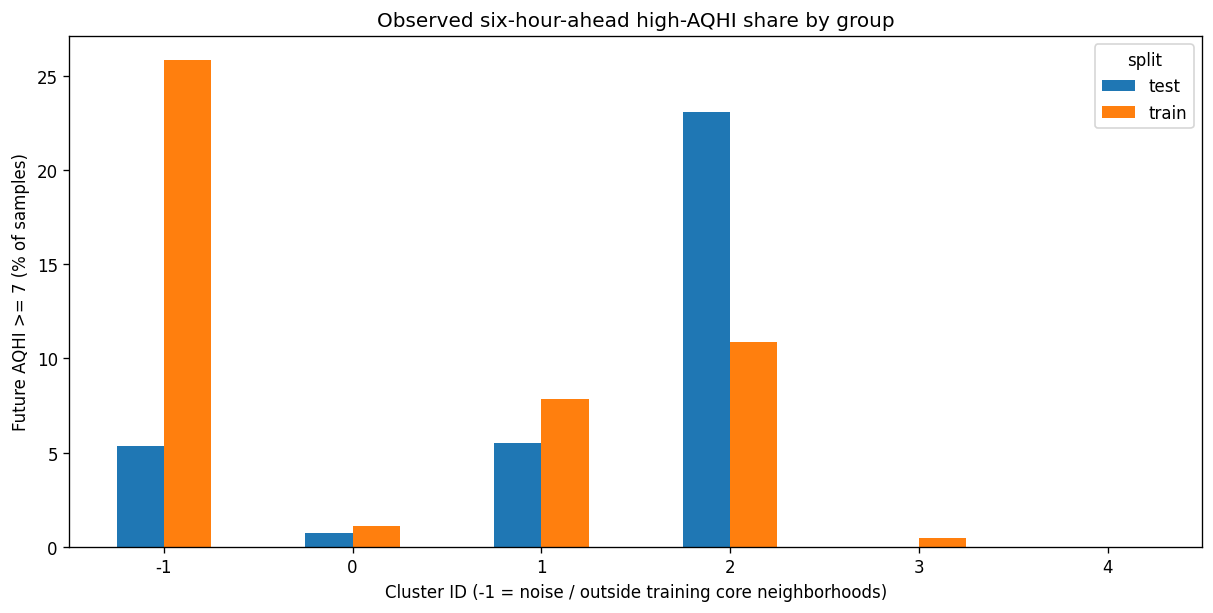

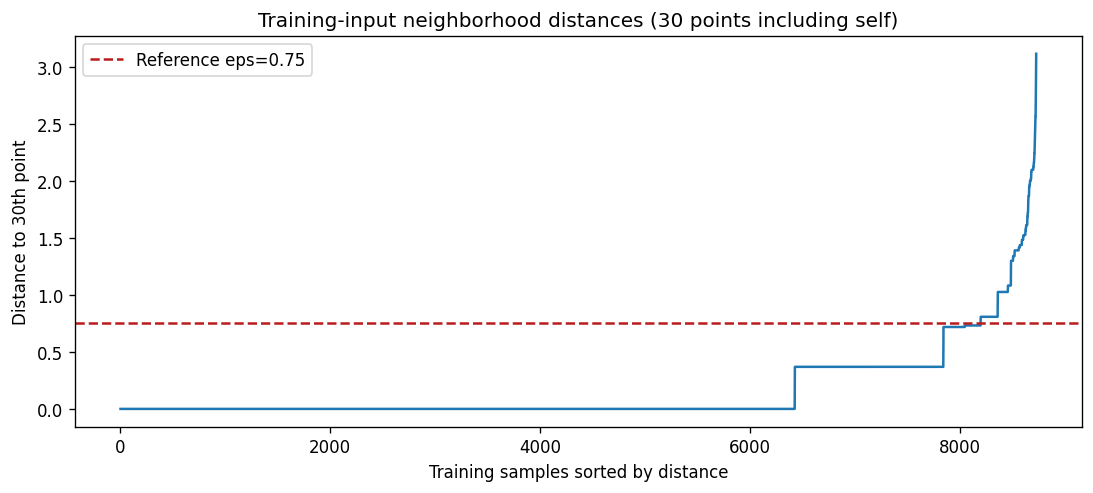

In [11]:
cluster_values = sorted(set(density_model.labels_) | set(test_cluster_labels))
colors = {label: ('#6b7280' if label == -1 else plt.get_cmap('tab10')(label % 10)) for label in cluster_values}
fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout='constrained')
for ax, assignments, split_name in zip(axes, cluster_frames, ['Train: native DBSCAN labels', 'Test: frozen training-core assignment']):
    for label in sorted(assignments.cluster.unique()):
        group = assignments.loc[assignments.cluster.eq(label)]
        ax.scatter(group.aqhi_now, group.aqhi_change_3h, s=14, alpha=0.45,
                   color=colors[label], label=('Noise / outside' if label == -1 else f'Cluster {label}'))
    ax.set(title=split_name, xlabel='Current AQHI (11 encodes 10+)', ylabel='Current minus three-hour-earlier AQHI')
    ax.legend(fontsize=8, loc='upper left')
fig.suptitle('DBSCAN four-feature clustering projected onto two features; eps=0.75, min_samples=30')
fig.savefig(figure_dir / 'dbscan_clusters.png', dpi=160)
plt.show()

rate_table = cluster_summary.pivot(index='cluster', columns='split', values='future_high_rate')
fig, ax = plt.subplots(figsize=(10, 5), layout='constrained')
(100 * rate_table).plot.bar(ax=ax)
ax.set(title='Observed six-hour-ahead high-AQHI share by group',
       xlabel='Cluster ID (-1 = noise / outside training core neighborhoods)',
       ylabel='Future AQHI >= 7 (% of samples)')
ax.tick_params(axis='x', labelrotation=0)
fig.savefig(figure_dir / 'dbscan_future_high_rates.png', dpi=160)
plt.show()

training_neighbors = NearestNeighbors(n_neighbors=DBSCAN_MIN_SAMPLES).fit(cluster_train_X)
k_distances = training_neighbors.kneighbors(cluster_train_X)[0][:, -1]
fig, ax = plt.subplots(figsize=(9, 4), layout='constrained')
ax.plot(np.sort(k_distances))
ax.axhline(DBSCAN_EPS, color='#b91c1c', linestyle='--', label=f'Reference eps={DBSCAN_EPS}')
ax.set(title='Training-input neighborhood distances (30 points including self)',
       xlabel='Training samples sorted by distance', ylabel='Distance to 30th point')
ax.legend()
fig.savefig(figure_dir / 'dbscan_neighbor_distances.png', dpi=160)
plt.show()

In [12]:
lookback_dir = output_dir / 'lookback_comparison'
lookback_dir.mkdir(exist_ok=True)
long_features = features.copy()
for lag in (4, 5, 6):
    long_features[f'aqhi_lag_{lag}h'] = observations['aqhi'].reindex(
        long_features.index - pd.Timedelta(hours=lag)
    ).to_numpy()
long_features['aqhi_change_6h'] = long_features['aqhi_now'] - long_features['aqhi_lag_6h']
lookback_feature_sets = {'3h': feature_columns, '6h': list(long_features.columns)}
comparison_samples = long_features.copy()
comparison_samples['target_time'] = comparison_samples.index + HORIZON
comparison_samples['actual_aqhi'] = observations['aqhi'].reindex(comparison_samples.target_time).to_numpy()
comparison_samples = comparison_samples.dropna(subset=list(long_features.columns) + ['actual_aqhi']).copy()
comparison_samples['actual_class'] = comparison_samples.actual_aqhi.ge(7).astype(int)
comparison_train = comparison_samples.loc[
    (comparison_samples.index < TEST_START) & (comparison_samples.target_time < TEST_START)
].copy()
comparison_test = comparison_samples.loc[
    (comparison_samples.index >= TEST_START) & (comparison_samples.target_time <= TEST_END)
].copy()
comparison_y_train = comparison_train.actual_class
comparison_y_test = comparison_test.actual_class
comparison_folds = list(TimeSeriesSplit(n_splits=3, gap=6).split(comparison_train))
for fit_rows, validation_rows in comparison_folds:
    assert comparison_train.iloc[fit_rows].target_time.max() < comparison_train.index[validation_rows].min()
    assert comparison_y_train.iloc[fit_rows].nunique() == 2
    assert comparison_y_train.iloc[validation_rows].sum() > 0
assert comparison_train.target_time.max() < comparison_test.index.min()
lookback_split_summary = pd.DataFrame([
    {'split': name, 'samples': len(frame), 'positives': int(frame.actual_class.sum()),
     'first_input': frame.index.min(), 'last_input': frame.index.max(), 'last_target': frame.target_time.max()}
    for name, frame in [('train', comparison_train), ('test', comparison_test)]
])
lookback_split_summary.to_csv(lookback_dir / 'split_summary.csv', index=False)
print(lookback_split_summary.to_string(index=False))
print('Input features:', {name: len(columns) for name, columns in lookback_feature_sets.items()})

split  samples  positives               first_input                last_input               last_target
train     8726        271 2025-04-01 07:00:00+08:00 2026-03-31 17:00:00+08:00 2026-03-31 23:00:00+08:00
 test     2146         34 2026-04-01 00:00:00+08:00 2026-06-30 18:00:00+08:00 2026-07-01 00:00:00+08:00
Input features: {'3h': 7, '6h': 11}


In [13]:
lookback_selected = {}
lookback_search_records = []
lookback_metrics_records = []
for lookback, columns in lookback_feature_sets.items():
    fit_X = comparison_train[columns]
    test_X = comparison_test[columns]
    lookback_selected[lookback] = {}
    result_frames = []
    for name, (base_estimator, grid) in model_specs.items():
        candidate_results = []
        for parameters in ParameterGrid(grid):
            fold_scores, fold_truth = [], []
            for fit_rows, validation_rows in comparison_folds:
                estimator = clone(base_estimator).set_params(**parameters)
                estimator.fit(fit_X.iloc[fit_rows], comparison_y_train.iloc[fit_rows])
                fold_scores.extend(scores_for(estimator, fit_X.iloc[validation_rows]))
                fold_truth.extend(comparison_y_train.iloc[validation_rows])
            fold_scores, fold_truth = np.asarray(fold_scores), np.asarray(fold_truth)
            threshold, validation_f1 = select_threshold(fold_truth, fold_scores)
            result = {'lookback': lookback, 'method': name, 'parameters': parameters,
                      'threshold': threshold, 'validation_f1': validation_f1,
                      'validation_precision': precision_score(fold_truth, fold_scores >= threshold, zero_division=0),
                      'validation_recall': recall_score(fold_truth, fold_scores >= threshold, zero_division=0)}
            candidate_results.append(result)
            lookback_search_records.append({**result, 'parameters': json.dumps(parameters, sort_keys=True)})
        best = max(candidate_results, key=lambda r: (r['validation_f1'], r['validation_precision']))
        lookback_selected[lookback][name] = best
        estimator = clone(base_estimator).set_params(**best['parameters'])
        estimator.fit(fit_X, comparison_y_train)
        test_scores = scores_for(estimator, test_X)
        predicted = (test_scores >= best['threshold']).astype(int)
        metric = {'lookback': lookback, **evaluate_predictions(name, comparison_y_test, predicted)}
        metric['average_precision'] = average_precision_score(comparison_y_test, test_scores)
        metric['validation_f1'] = best['validation_f1']
        metric['threshold'] = best['threshold']
        lookback_metrics_records.append(metric)
        frame = comparison_test[['target_time', 'actual_aqhi', 'actual_class']].reset_index()
        frame['lookback'], frame['method'] = lookback, name
        frame['predicted_class'], frame['score'], frame['threshold'] = predicted, test_scores, best['threshold']
        frame['score_type'] = 'decision_function' if name == 'SVM' else 'predict_proba'
        result_frames.append(frame)
        print(lookback, name, 'validation F1:', round(best['validation_f1'], 4), 'test F1:', round(metric['f1'], 4), flush=True)
    baseline_predicted = comparison_test.aqhi_now.ge(7).astype(int).to_numpy()
    lookback_metrics_records.append({
        'lookback': lookback, **evaluate_predictions('Persistence baseline', comparison_y_test, baseline_predicted),
        'average_precision': average_precision_score(comparison_y_test, baseline_predicted),
        'validation_f1': np.nan, 'threshold': 0.5})
    baseline_frame = comparison_test[['target_time', 'actual_aqhi', 'actual_class']].reset_index()
    baseline_frame['lookback'], baseline_frame['method'] = lookback, 'Persistence baseline'
    baseline_frame['predicted_class'], baseline_frame['score'], baseline_frame['threshold'] = baseline_predicted, baseline_predicted, 0.5
    baseline_frame['score_type'] = 'binary_baseline'
    result_frames.append(baseline_frame)
    pd.concat(result_frames, ignore_index=True).to_csv(lookback_dir / f'test_predictions_{lookback}.csv', index=False)

lookback_metrics = pd.DataFrame(lookback_metrics_records)
lookback_metrics.to_csv(lookback_dir / 'test_metrics.csv', index=False)
pd.DataFrame(lookback_search_records).to_csv(lookback_dir / 'validation_search.csv', index=False)
paired = lookback_metrics.pivot(index='method', columns='lookback', values=['precision','recall','f1','validation_f1'])
paired.columns = ['_'.join(column) for column in paired.columns]
paired['test_f1_change_6h_minus_3h'] = paired.f1_6h - paired.f1_3h
paired['validation_f1_change_6h_minus_3h'] = paired.validation_f1_6h - paired.validation_f1_3h
paired.to_csv(lookback_dir / 'paired_comparison.csv')
lookback_validation_choice = max(
    [result for methods in lookback_selected.values() for result in methods.values()],
    key=lambda r: (r['validation_f1'], r['validation_precision'])
)
lookback_settings = {
    'forecast_horizon_hours': 6,
    'feature_sets': lookback_feature_sets,
    'cohort': 'identical complete six-hour-history cases for both lookbacks',
    'test_start': TEST_START.isoformat(), 'test_target_end': TEST_END.isoformat(),
    'validation': 'three expanding chronological folds with six-row gap; all target boundaries checked',
    'selection': 'pooled validation F1; thresholds and parameters retuned separately for each feature set',
    'selected_models': lookback_selected,
    'validation_selected_configuration': lookback_validation_choice,
    'test_interpretation': 'exploratory comparison on an already inspected holdout',
    'train_samples': len(comparison_train), 'test_samples': len(comparison_test),
    'train_positives': int(comparison_y_train.sum()), 'test_positives': int(comparison_y_test.sum()),
    'input_sha256': hashlib.sha256(data_path.read_bytes()).hexdigest(),
}
(lookback_dir / 'settings.json').write_text(json.dumps(lookback_settings, indent=2), encoding='utf-8')
print(paired.to_string())
print('Validation-selected configuration:', json.dumps(lookback_validation_choice))

3h Decision Tree validation F1: 0.2439 test F1: 0.25


3h Random Forest validation F1: 0.2518 test F1: 0.2384


3h Logistic Regression validation F1: 0.3425 test F1: 0.2597


3h KNN validation F1: 0.2164 test F1: 0.1918


3h SVM validation F1: 0.2209 test F1: 0.2414


6h Decision Tree validation F1: 0.2489 test F1: 0.198


6h Random Forest validation F1: 0.2578 test F1: 0.2481


6h Logistic Regression validation F1: 0.3372 test F1: 0.2667


6h KNN validation F1: 0.1978 test F1: 0.1719


6h SVM validation F1: 0.2217 test F1: 0.25


                      precision_3h  precision_6h  recall_3h  recall_6h     f1_3h     f1_6h  validation_f1_3h  validation_f1_6h  test_f1_change_6h_minus_3h  validation_f1_change_6h_minus_3h
method                                                                                                                                                                                      
Decision Tree             0.217391      0.149254   0.294118   0.294118  0.250000  0.198020          0.243902          0.248889                   -0.051980                          0.004986
KNN                       0.179487      0.117021   0.205882   0.323529  0.191781  0.171875          0.216359          0.197802                   -0.019906                         -0.018557
Logistic Regression       0.232558      0.243902   0.294118   0.294118  0.259740  0.266667          0.342508          0.337209                    0.006926                         -0.005298
Persistence baseline      0.176471      0.176471   0.17

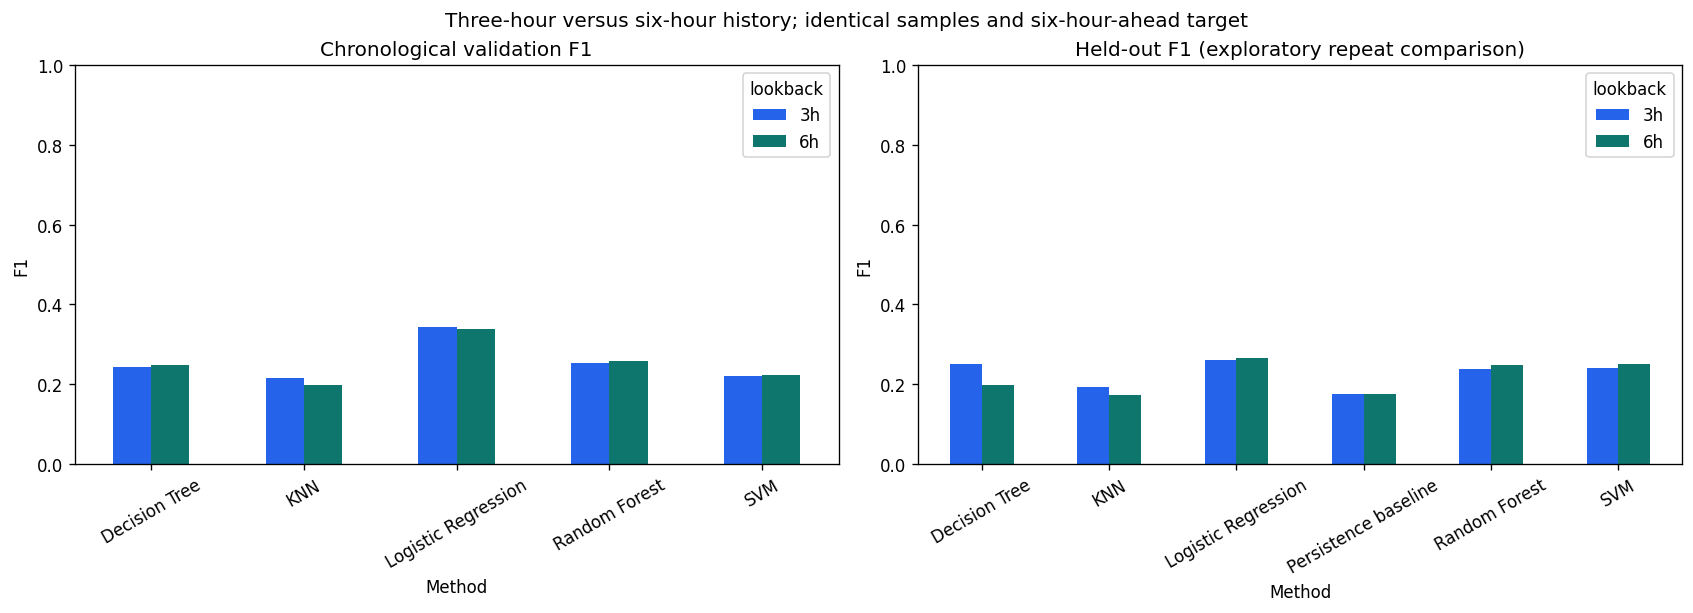

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), layout='constrained')
for ax, metric_name, title in zip(axes, ['validation_f1','f1'], ['Chronological validation F1', 'Held-out F1 (exploratory repeat comparison)']):
    values = lookback_metrics.pivot(index='method', columns='lookback', values=metric_name)
    if metric_name == 'validation_f1':
        values = values.drop(index='Persistence baseline')
    values.plot.bar(ax=ax, color=['#2563eb','#0f766e'])
    ax.set(title=title, xlabel='Method', ylabel='F1', ylim=(0, 1))
    ax.tick_params(axis='x', labelrotation=30)
fig.suptitle('Three-hour versus six-hour history; identical samples and six-hour-ahead target')
fig.savefig(figure_dir / 'lookback_f1_comparison.png', dpi=160)
plt.show()